# Barridos en $x$ (AUTOX): gráficos sin ajustes, medidos y con el piso restado

Gráficos cualitativos de los barridos en $x$: $S/S_0$ contra $x$ uniendo los puntos medidos, **sin ajustar ningún modelo**, una vez con la señal
medida y otra con el piso de ruido de la magnitud restado. Sirven para ver el comportamiento de las fibras frente al agua libre en cada dirección,
donde el ajuste libre de $D_0$ no describe las fibras (`nogse_fits_autox*.ipynb` tienen los ajustes).

Cada archivo AUTOX es una serie con un $G$ fijo: 2 b0 y, para 20 valores de $x$ entre 0 (Hahn puro) y $T/N$ (CPMG), las direcciones 1, 2, 3 del
escáner ($x$, $y$, $z$). $x$ de cada volumen sale de su $b$ exacto (ingest, `add_x_sweep_derivatives`); $S_0$ es la media de los b0 de la misma
serie. Para agua libre la señal crece con $x$ ($b$ baja de Hahn a CPMG); en una restricción la forma depende del tamaño.

**Orden de adquisición.** En v2.00.3 el primer volumen pesado es $x = 0$, y en el agua los primeros volúmenes después de los b0 salieron
más altos que el resto (transitorio, ver `docs/versions/v2.00.4/v2.00.4.tex` del repositorio NOGSE): el punto $x=0$ de esas series está
afectado. Desde v2.00.4 el barrido va de $T/N$ a 0 y hay 10 dummies pesados.

Salidas en `signal_analysis/results/autox_plots/sub-<SUB>/ses-<SESSION_ID>/`.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.optimize import minimize_scalar


def find_project_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    for candidate in (start, *start.parents):
        if (candidate / 'Data-BIDS').is_dir() and (candidate / 'repos' / 'signal_analysis').is_dir():
            return candidate
    raise FileNotFoundError('No encuentro la raíz del proyecto.')


PROJECT_ROOT = find_project_root()
REPO_ROOT = PROJECT_ROOT / 'repos' / 'signal_analysis'
SRC_ROOT = REPO_ROOT / 'src'
if str(SRC_ROOT) not in sys.path:
    sys.path.insert(0, str(SRC_ROOT))

from data_processing.result_signals import X_SWEEP_NAME

plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.max_columns', 50)
PROJECT_ROOT

PosixPath('/mnt/storage/tier2/MUMI-EXT-001/mumi-data/Project-NOGSE')

## Configuración

`SESSION_ID` es la sesión del barrido en $x$ y `FLOOR_SESSION_ID` la sesión $G$ (AUTOG) del mismo fantoma de la que se mide el piso.
`ROIS = None` usa todos los ROIs del barrido.

In [2]:
ANALYSIS_TAG = 'den_gr--manual'  # alternativa: 'raw--manual'
SUB = 'PHANTOM-3'
SESSION_ID = '20261026NOGSEV2003FOV220M128SL01R1AUTOX'
FLOOR_SESSION_ID = '20261026NOGSEV2001FOV220M128SL01R1G070AUTOG'
ROIS = None  # p. ej. ['water1', 'fiber1']; None: todos
STAT = 'avg'

FLOOR_ROIS = ['water1', 'water2']  # free-water ROIs whose plateau gives F
FLOOR_FREE_MIN_SIGNAL = 0.2        # reference D0 only from points with S/S0 >= 0.2
PLATEAU_MAX_SIGNAL = 0.003         # plateau points: predicted attenuation below 0.3 %
FLOOR_F_OVERRIDE = None            # scanner units; set it to skip the plateau measurement

NUMERIC = ['td_ms', 'TN', 'N', 'x', 'G', 'g', 'ramp_time_ms', 'bvalue', 'b_step', 'value', 'S0', 'value_norm']
MASTER_PATH = (PROJECT_ROOT / 'Data-BIDS' / 'derivatives' / 'signal_analysis' /
               ANALYSIS_TAG / 'phantoms' / 'nogse_experiments' / 'master.long.parquet')
master = pd.read_parquet(MASTER_PATH)
master_types = master['type'].astype(str).str.strip().str.upper()
is_sweep = master_types.eq('AUTOX') | master['protocol'].astype(str).str.contains(X_SWEEP_NAME)


def select_rows(session_id, kind, rois=None):
    # Weighted volumes (b_step > 0) of one session: kind 'autox' (x sweep) or 'autog' (CPMG and Hahn G series).
    subject = master['subj'].astype(str) == SUB
    sessions = sorted(master.loc[subject, 'session_id'].dropna().astype(str).unique())
    if session_id not in sessions:
        raise ValueError(f'SESSION_ID={session_id!r} is not in the master for {SUB}. Available: {sessions}')
    kind_mask = is_sweep if kind == 'autox' else (~is_sweep & master_types.isin(['CPMG', 'HAHN']))
    rows = master.loc[subject & (master['session_id'].astype(str) == session_id) &
                      (master['stat'].astype(str) == STAT) & kind_mask].copy()
    available_rois = sorted(rows['roi'].astype(str).unique())
    if rois is not None:
        missing = [roi for roi in rois if roi not in available_rois]
        if missing:
            raise ValueError(f'ROIs {missing} not in {SUB}, {session_id} ({kind}). Available: {available_rois}')
        rows = rows.loc[rows['roi'].astype(str).isin(rois)]
    if rows.empty:
        raise ValueError(f'No {kind} rows in {SUB}, {session_id}.')
    for column in NUMERIC:
        rows[column] = pd.to_numeric(rows[column], errors='coerce')
    rows['type'] = rows['type'].astype(str).str.strip().str.upper()
    rows['roi'] = rows['roi'].astype(str)
    rows['direction'] = rows['direction'].astype(str)
    return rows.loc[rows['b_step'] > 0].dropna(subset=['bvalue', 'value', 'S0', 'value_norm'])

OUTPUT_ROOT = REPO_ROOT / 'results' / 'autox_plots' / f'sub-{SUB}' / f'ses-{SESSION_ID}'
FIGURE_DIR = OUTPUT_ROOT / 'figures'
TABLE_DIR = OUTPUT_ROOT / 'tables'
for folder in (FIGURE_DIR, TABLE_DIR):
    folder.mkdir(parents=True, exist_ok=True)

data = select_rows(SESSION_ID, 'autox', ROIS)
rois = sorted(data['roi'].unique())
g_values = sorted(data['G'].unique())
directions = sorted(data['direction'].unique())
print('Master:', MASTER_PATH)
print('Salida:', OUTPUT_ROOT)
display(data.groupby(['roi', 'G']).agg(n=('x', 'size'), x_min=('x', 'min'), x_max=('x', 'max'), TN=('TN', 'first'),
                                       S0=('S0', 'first')).reset_index())

Master: /mnt/storage/tier2/MUMI-EXT-001/mumi-data/Project-NOGSE/Data-BIDS/derivatives/signal_analysis/den_gr--manual/phantoms/nogse_experiments/master.long.parquet
Salida: /mnt/storage/tier2/MUMI-EXT-001/mumi-data/Project-NOGSE/repos/signal_analysis/results/autox_plots/sub-PHANTOM-3/ses-20261026NOGSEV2003FOV220M128SL01R1AUTOX


,roi,G,n,x_min,x_max,TN,S0
0,fiber1,10.0,60,0.0,25.0,50.0,103.582603
1,fiber1,20.0,60,0.0,25.0,50.0,103.667223
2,fiber1,30.0,60,0.0,25.0,50.0,103.349486
3,fiber2,10.0,60,0.0,25.0,50.0,21.274085
4,fiber2,20.0,60,0.0,25.0,50.0,21.007894
5,fiber2,30.0,60,0.0,25.0,50.0,21.115046
6,water1,10.0,60,0.0,25.0,50.0,268.514124
7,water1,20.0,60,0.0,25.0,50.0,263.687271
8,water1,30.0,60,0.0,25.0,50.0,263.975727
9,water2,10.0,60,0.0,25.0,50.0,276.055549


## Piso de ruido de la magnitud

Igual que en los notebooks de ajuste con piso: $F$ (unidades del escáner) es la media de `value` en los puntos de meseta del agua libre de la sesión
`FLOOR_SESSION_ID` (`FLOOR_ROIS`): los puntos cuya atenuación predicha con un $D_0$ de referencia es menor que `PLATEAU_MAX_SIGNAL`; el $D_0$ de
referencia de cada ROI de agua sale de $e^{-bD_0}$ ajustado a sus puntos con $S/S_0 \ge$ `FLOOR_FREE_MIN_SIGNAL`. `FLOOR_F_OVERRIDE` impone $F$.
Señal con el piso restado:

$$a=\frac{\sqrt{\max(S^2-F^2,\,0)}}{\sqrt{S_0^2-F^2}}.$$

El piso cambia con la posición: en PHANTOM-3 la meseta de `fiber1` (≈ 12.5) está por debajo del $F$ del agua (≈ 16.8), así que en las fibras la
versión corregida puede estar sobrecorregida. `fiber2` tiene $S_0$ apenas por encima del piso: su señal es casi solo ruido.

In [3]:
def reference_d0(points):
    # D0 (mm^2/s) of exp(-b D0), M0 = 1, fitted to the points with S/S0 >= FLOOR_FREE_MIN_SIGNAL
    keep = points['value_norm'] >= FLOOR_FREE_MIN_SIGNAL
    b, s = points.loc[keep, 'bvalue'].to_numpy(float), points.loc[keep, 'value_norm'].to_numpy(float)
    result = minimize_scalar(lambda log_d0: np.mean((s - np.exp(-b * np.exp(log_d0)))**2),
                             bounds=np.log([1e-4, 1e-2]), method='bounded')
    return float(np.exp(result.x))


if FLOOR_F_OVERRIDE is not None:
    FLOOR_F = float(FLOOR_F_OVERRIDE)
    print(f'Floor F = {FLOOR_F:.2f} (FLOOR_F_OVERRIDE)')
else:
    floor_rows = select_rows(FLOOR_SESSION_ID, 'autog', FLOOR_ROIS)
    floor_d0 = {roi: reference_d0(rows) for roi, rows in floor_rows.groupby('roi')}
    floor_rows['a_predicted'] = np.exp(-floor_rows['bvalue'] * floor_rows['roi'].map(floor_d0))
    plateau = floor_rows.loc[floor_rows['a_predicted'] < PLATEAU_MAX_SIGNAL]
    if plateau.empty:
        raise ValueError('No plateau points: raise PLATEAU_MAX_SIGNAL or set FLOOR_F_OVERRIDE.')
    FLOOR_F = float(plateau['value'].mean())
    for roi, d0 in floor_d0.items():
        print(f'Reference D0 of {roi}: {d0 * 1e3:.3f} x 1e-3 mm²/s')
    print(f'Floor F = {FLOOR_F:.2f} (scanner units) from {len(plateau)} plateau points of {FLOOR_ROIS} in {FLOOR_SESSION_ID}')
    display(plateau.groupby('roi').agg(n=('value', 'size'), F=('value', 'mean'), s_mean=('value_norm', 'mean')).round(3))

data['value_norm_corr'] = (np.sqrt(np.clip(data['value']**2 - FLOOR_F**2, 0, None)) /
                           np.sqrt(np.clip(data['S0']**2 - FLOOR_F**2, 0, None)).replace(0, np.nan))
floor_table = data.groupby('roi').agg(S0=('S0', 'mean')).reset_index()
floor_table['c_floor'] = FLOOR_F / floor_table['S0']
floor_table['n_below_floor'] = data.groupby('roi')['value'].apply(lambda v: int((v < FLOOR_F).sum())).to_numpy()
floor_table.insert(0, 'F_scanner_units', FLOOR_F)
floor_table.to_csv(TABLE_DIR / 'noise_floor.csv', index=False)
display(floor_table.round(4))
for roi in floor_table.loc[floor_table['c_floor'] > 0.5, 'roi']:
    print(f'ATENCIÓN: {roi} tiene F/S0 > 0.5: su señal está casi entera sobre el piso.')

CORRECTIONS = {'medido': 'value_norm', 'piso restado': 'value_norm_corr'}
direction_colors = {'1': 'tab:blue', '2': 'tab:orange', '3': 'tab:green'}
direction_names = {'1': 'dirección 1 (x)', '2': 'dirección 2 (y)', '3': 'dirección 3 (z)'}
roi_styles = {'water1': ('tab:blue', 'o'), 'water2': ('tab:cyan', 's'), 'fiber1': ('tab:red', '^'), 'fiber2': ('tab:orange', 'v')}


def roi_style(roi):
    return roi_styles.get(roi, ('0.3', 'D'))


def save_figure(fig, folder, stem):
    fig.savefig(folder / f'{stem}.png', dpi=160, bbox_inches='tight')
    fig.savefig(folder / f'{stem}.pdf', bbox_inches='tight')

Reference D0 of water1: 3.167 x 1e-3 mm²/s
Reference D0 of water2: 3.023 x 1e-3 mm²/s
Floor F = 16.75 (scanner units) from 42 plateau points of ['water1', 'water2'] in 20261026NOGSEV2001FOV220M128SL01R1G070AUTOG


,n,F,s_mean
roi,,,
water1,21,17.249,0.064
water2,21,16.256,0.060


,F_scanner_units,roi,S0,c_floor,n_below_floor
0,16.7524,fiber1,103.5331,0.1618,0
1,16.7524,fiber2,21.1323,0.7927,0
2,16.7524,water1,265.3924,0.0631,0
3,16.7524,water2,269.5348,0.0622,0


ATENCIÓN: fiber2 tiene F/S0 > 0.5: su señal está casi entera sobre el piso.


## Fibras contra agua: una figura por dirección

Filas: señal medida y con el piso restado. Columnas: $G$. Una curva por ROI (puntos unidos, sin ajuste).

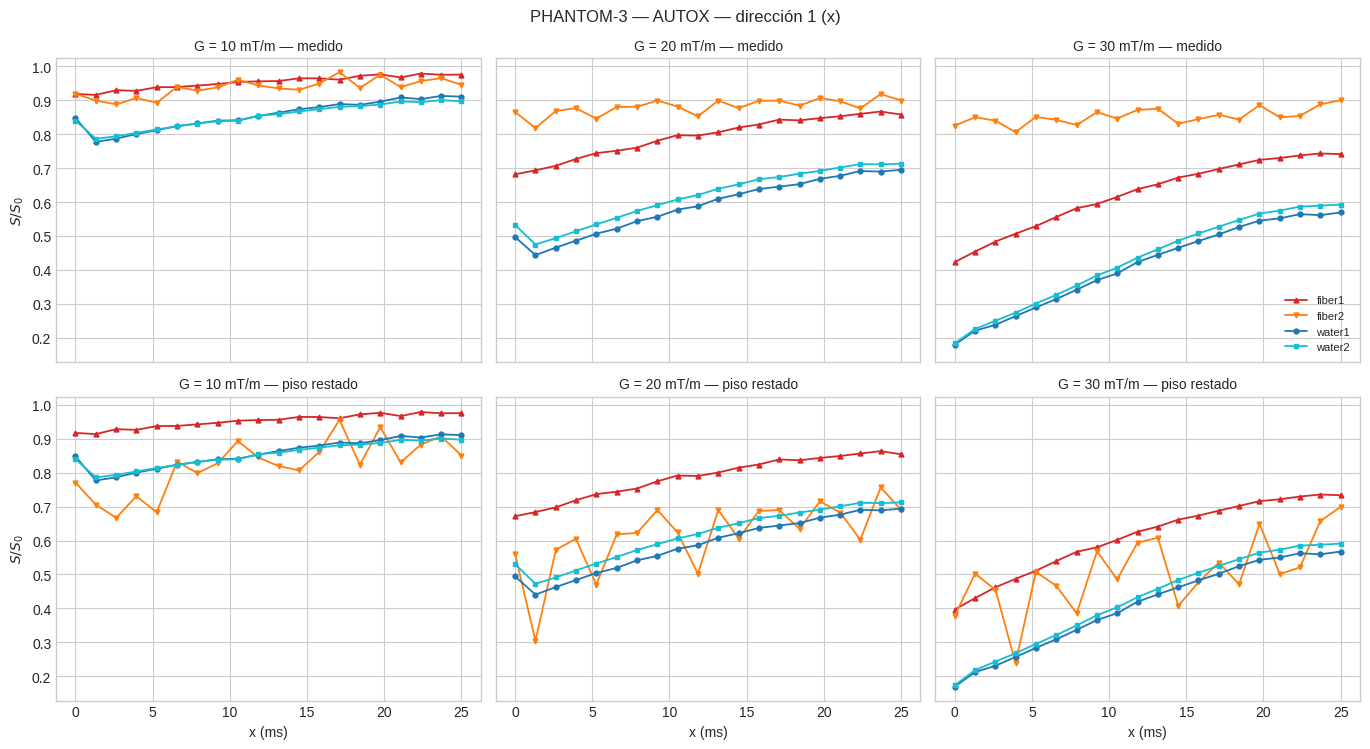

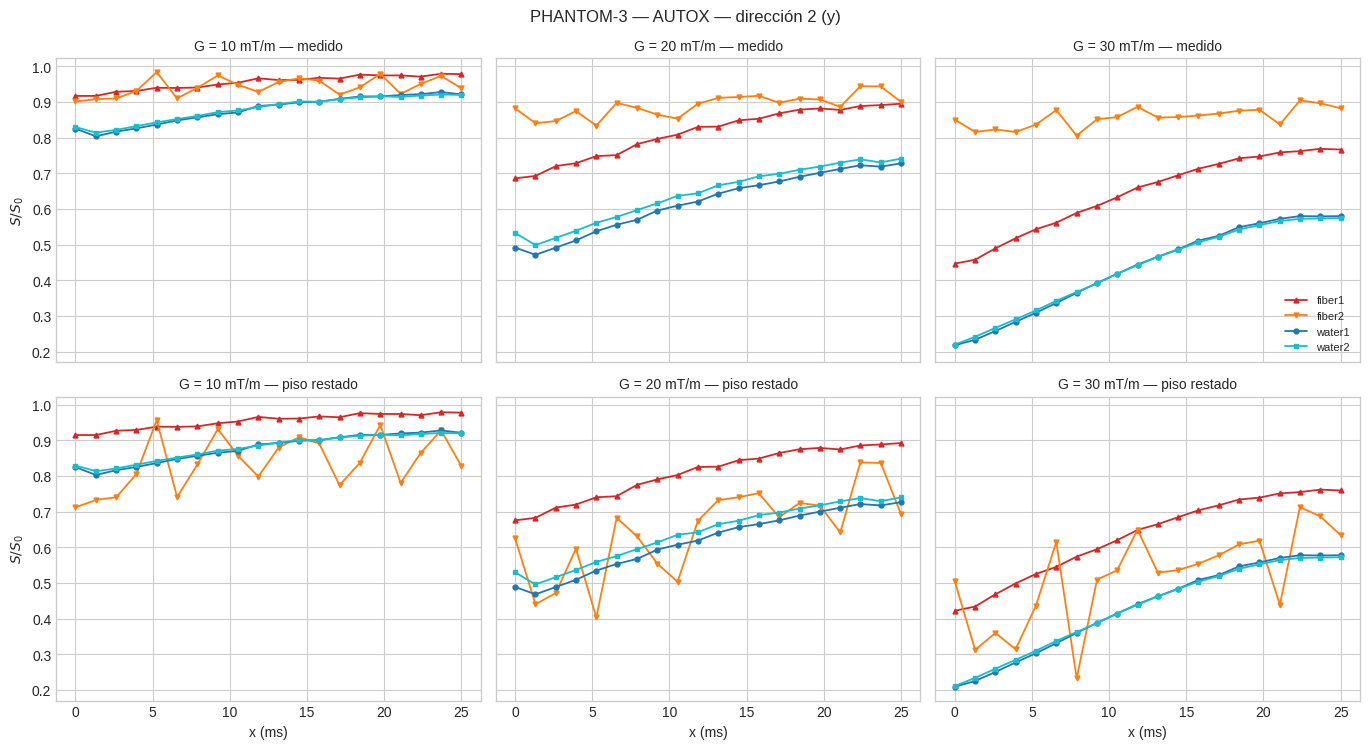

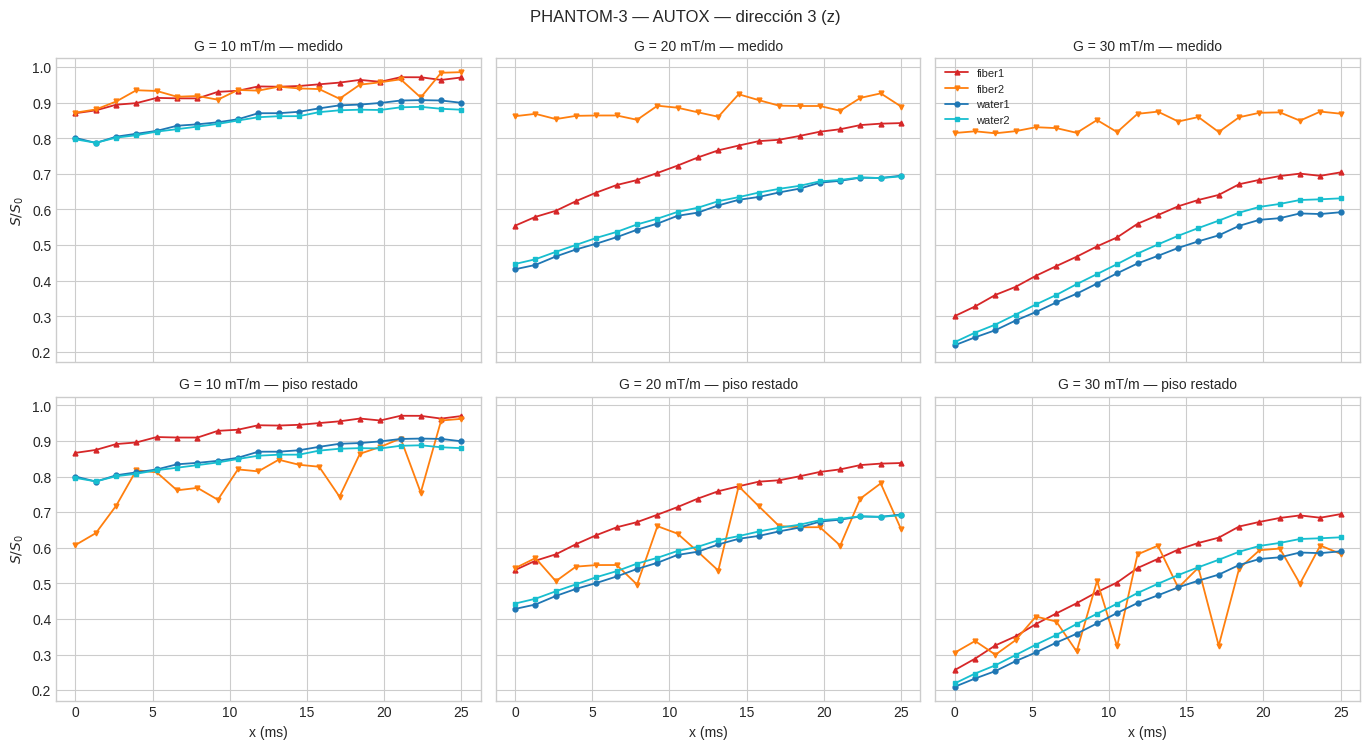

In [4]:
def plot_curve(ax, curve, column, color, marker, label):
    curve = curve.sort_values('x')
    ax.plot(curve['x'], curve[column], '-', marker=marker, color=color, ms=3.5, lw=1.3, label=label)


for direction in directions:
    fig, axes = plt.subplots(len(CORRECTIONS), len(g_values), figsize=(4.6 * len(g_values), 3.8 * len(CORRECTIONS)),
                             sharex=True, sharey=True, squeeze=False)
    for row, (correction, column) in enumerate(CORRECTIONS.items()):
        for col, g_value in enumerate(g_values):
            ax = axes[row, col]
            for roi in rois:
                curve = data.loc[data['roi'].eq(roi) & data['G'].eq(g_value) & data['direction'].eq(direction)]
                color, marker = roi_style(roi)
                plot_curve(ax, curve, column, color, marker, roi)
            ax.set_title(f'G = {g_value:g} mT/m — {correction}', fontsize=10)
            if row == len(CORRECTIONS) - 1:
                ax.set_xlabel('x (ms)')
            if col == 0:
                ax.set_ylabel('$S/S_0$')
    axes[0, -1].legend(fontsize=8)
    fig.suptitle(f'{SUB} — AUTOX — {direction_names.get(direction, direction)}', fontsize=12)
    fig.tight_layout()
    save_figure(fig, FIGURE_DIR, f'autox_rois_direction-{direction}')
    plt.show()

## Una figura por ROI: las tres direcciones

Para ver la anisotropía de cada ROI (en el agua libre las tres direcciones deben coincidir).

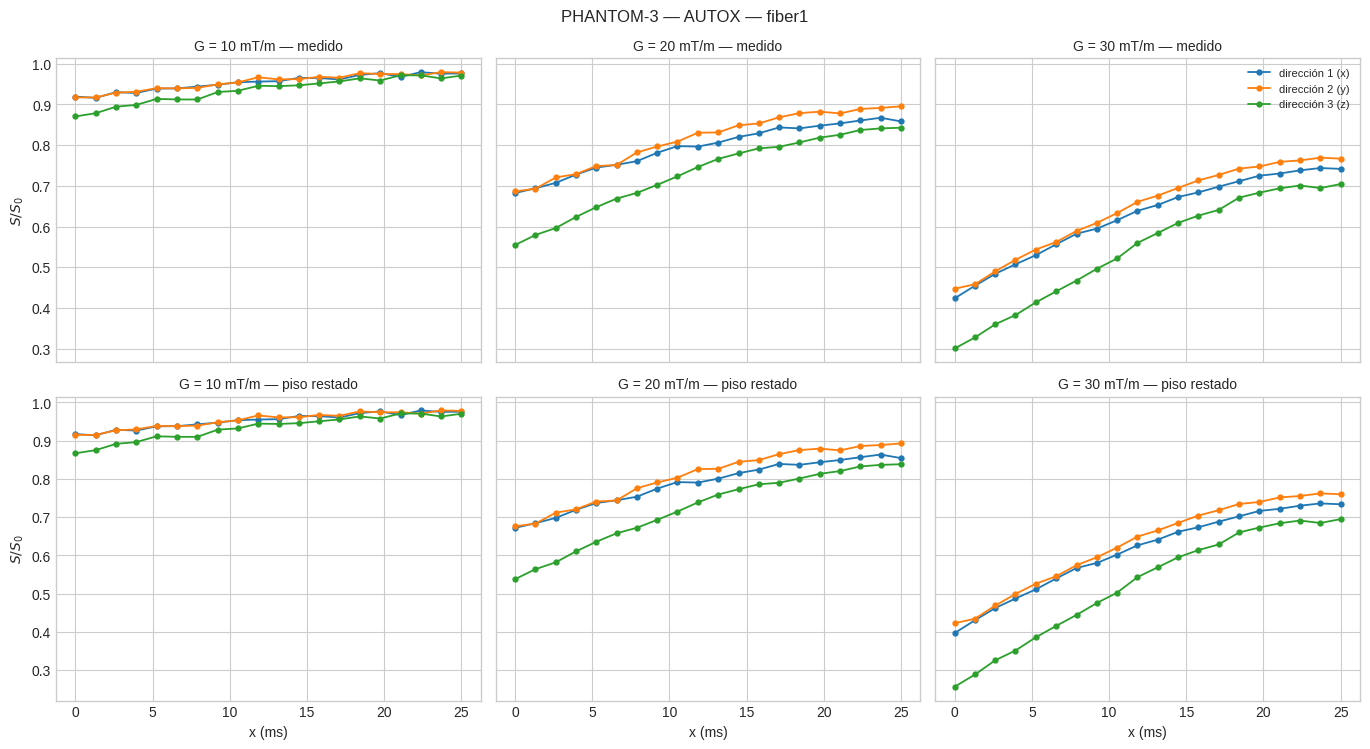

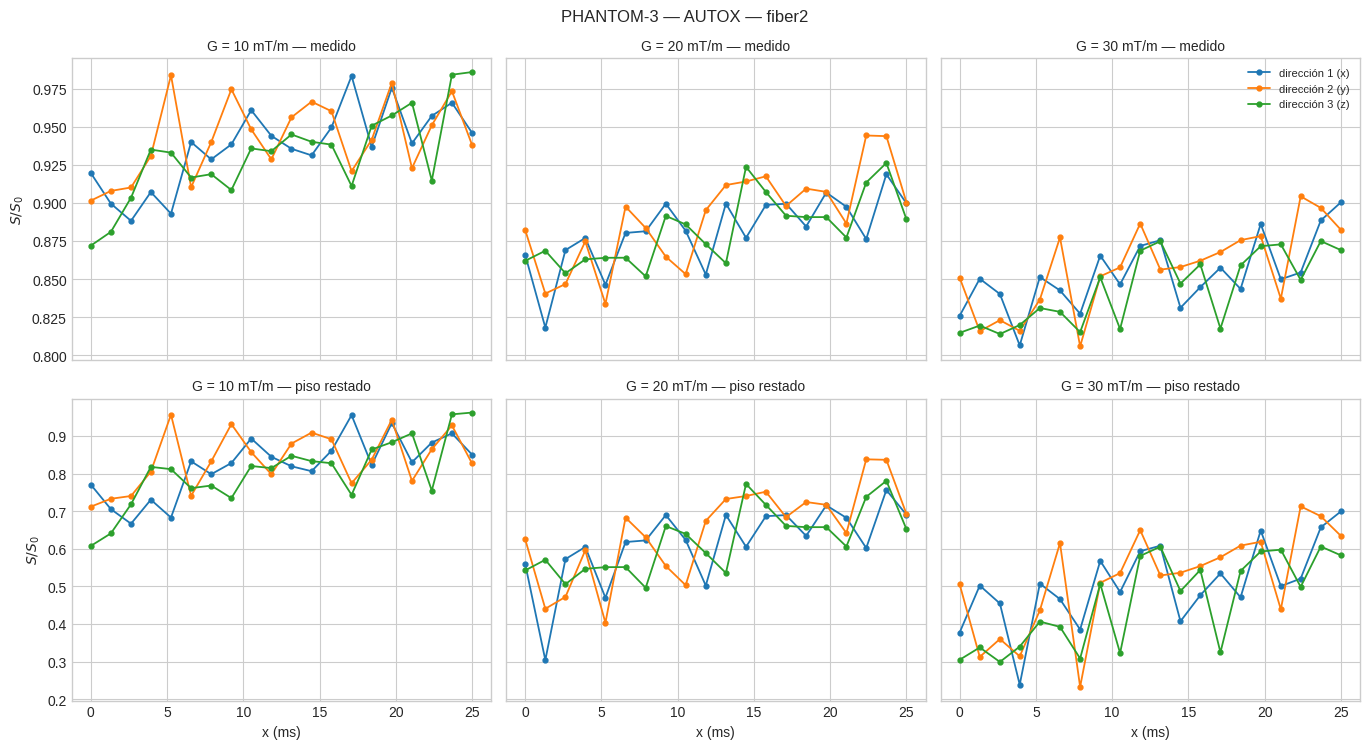

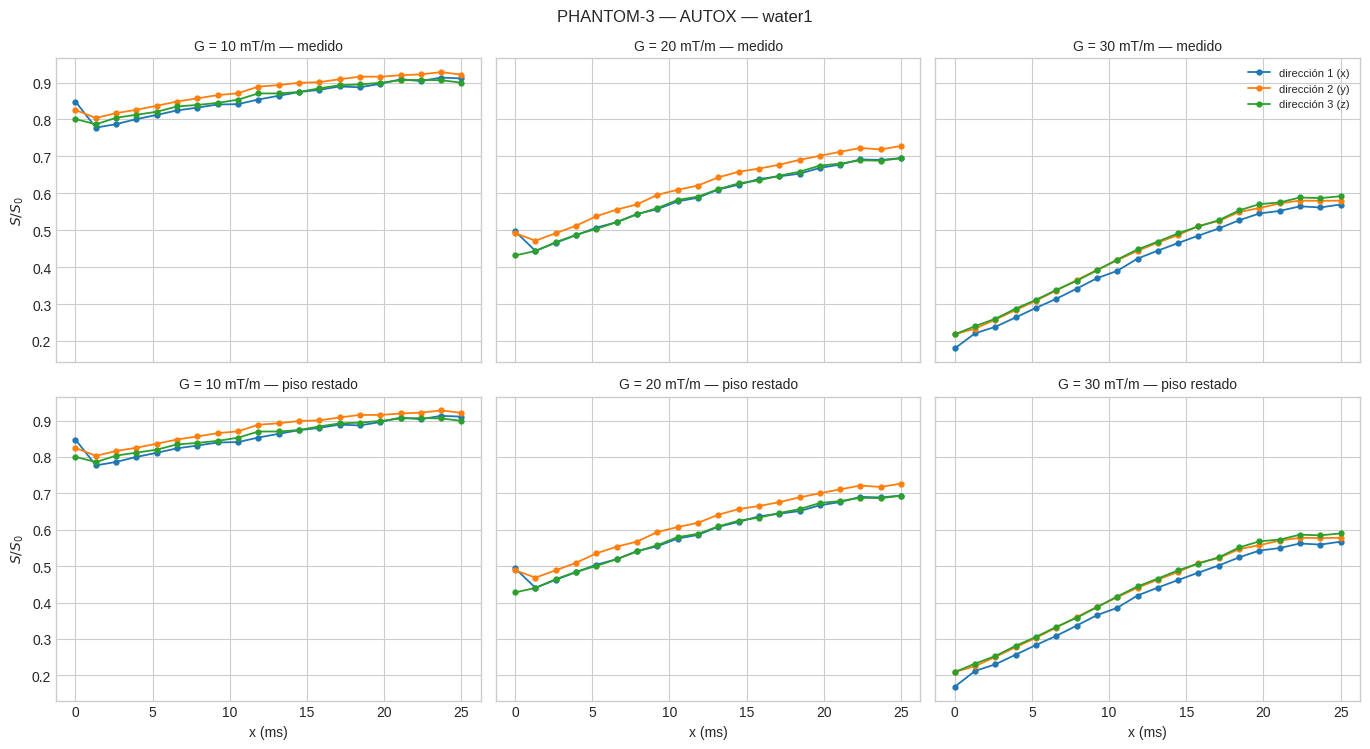

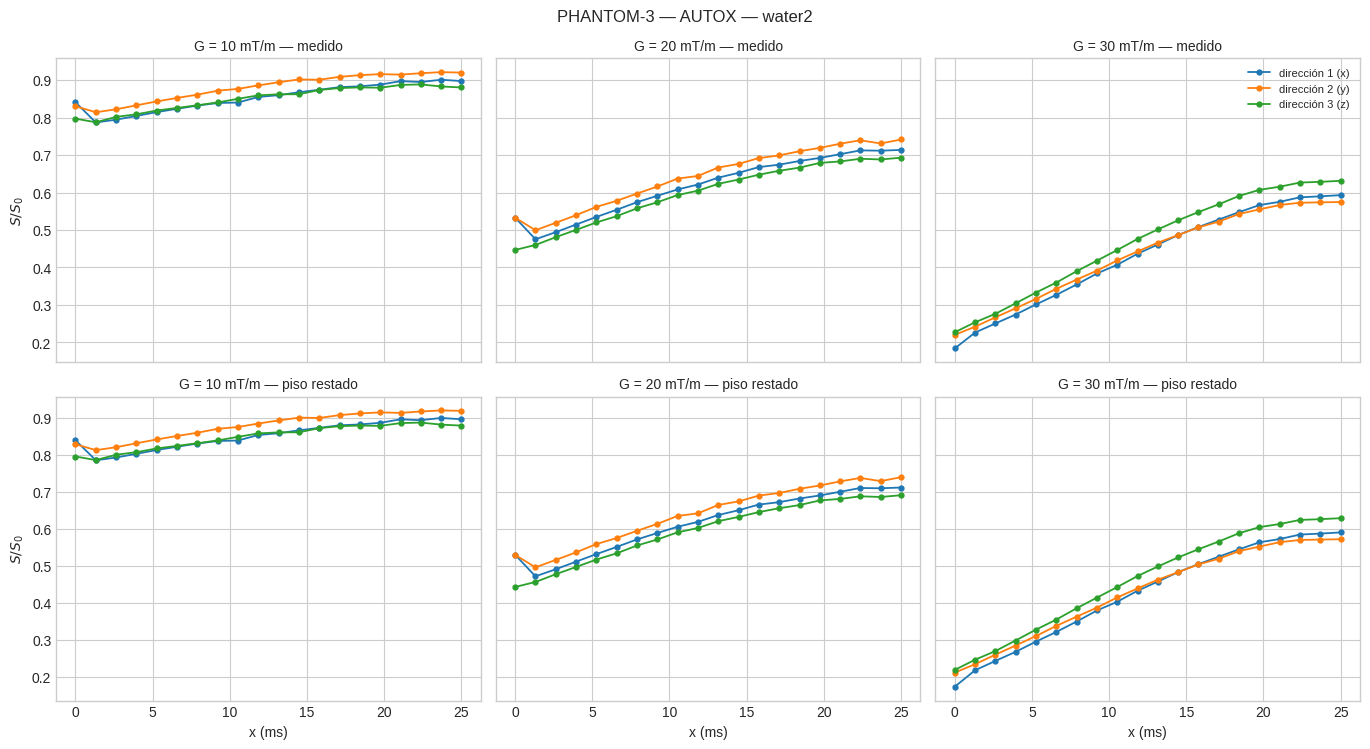

In [5]:
for roi in rois:
    fig, axes = plt.subplots(len(CORRECTIONS), len(g_values), figsize=(4.6 * len(g_values), 3.8 * len(CORRECTIONS)),
                             sharex=True, sharey='row', squeeze=False)
    for row, (correction, column) in enumerate(CORRECTIONS.items()):
        for col, g_value in enumerate(g_values):
            ax = axes[row, col]
            for direction in directions:
                curve = data.loc[data['roi'].eq(roi) & data['G'].eq(g_value) & data['direction'].eq(direction)]
                plot_curve(ax, curve, column, direction_colors.get(direction), 'o', direction_names.get(direction, direction))
            ax.set_title(f'G = {g_value:g} mT/m — {correction}', fontsize=10)
            if row == len(CORRECTIONS) - 1:
                ax.set_xlabel('x (ms)')
            if col == 0:
                ax.set_ylabel('$S/S_0$')
    axes[0, -1].legend(fontsize=8)
    fig.suptitle(f'{SUB} — AUTOX — {roi}', fontsize=12)
    fig.tight_layout()
    save_figure(fig, FIGURE_DIR, f'autox_{roi}_directions')
    plt.show()

## Contraste respecto del límite Hahn, $\Delta M(x) = M(x) - M(0)$

Punto a punto dentro de cada serie (mismo ROI, $G$ y dirección), con la señal medida y con el piso restado. En $x = T/N$ es el contraste CPMG − Hahn
ideal. Ojo: en las series de v2.00.3, $M(0)$ es el primer volumen pesado (ver arriba).

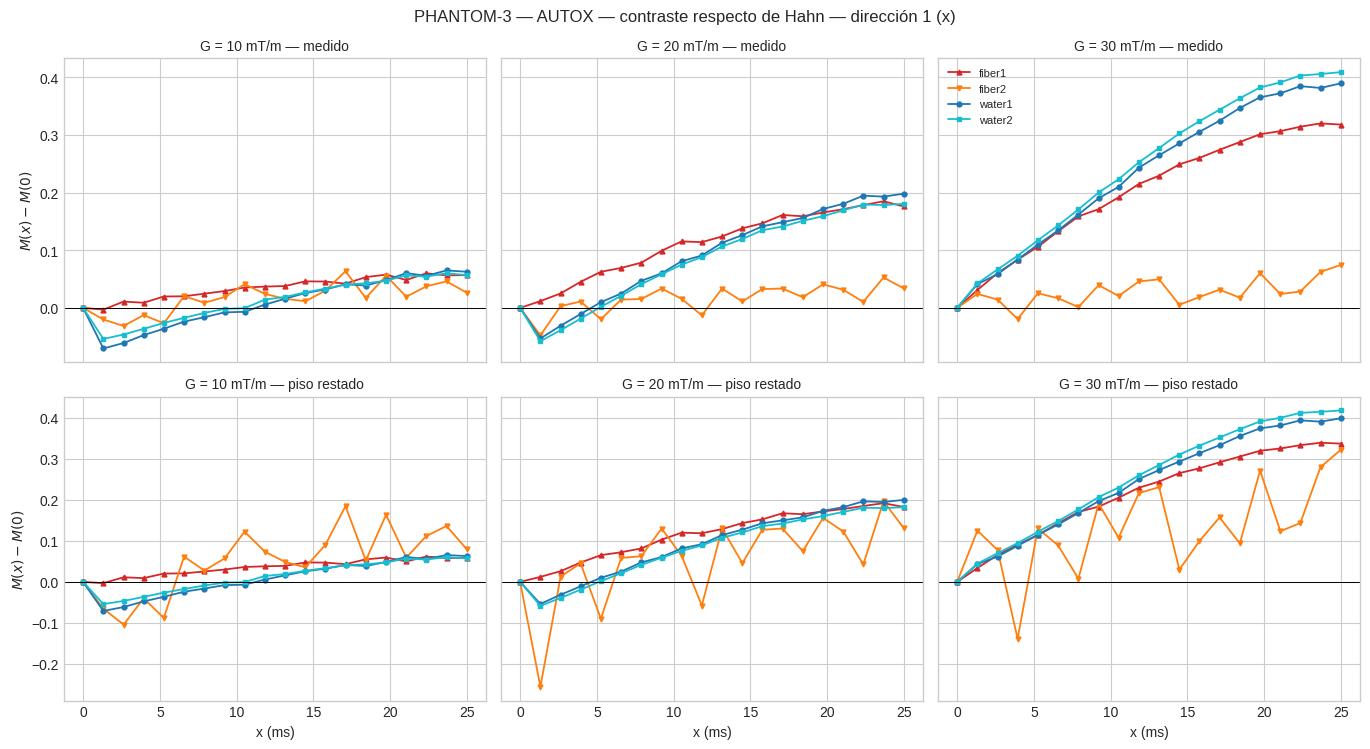

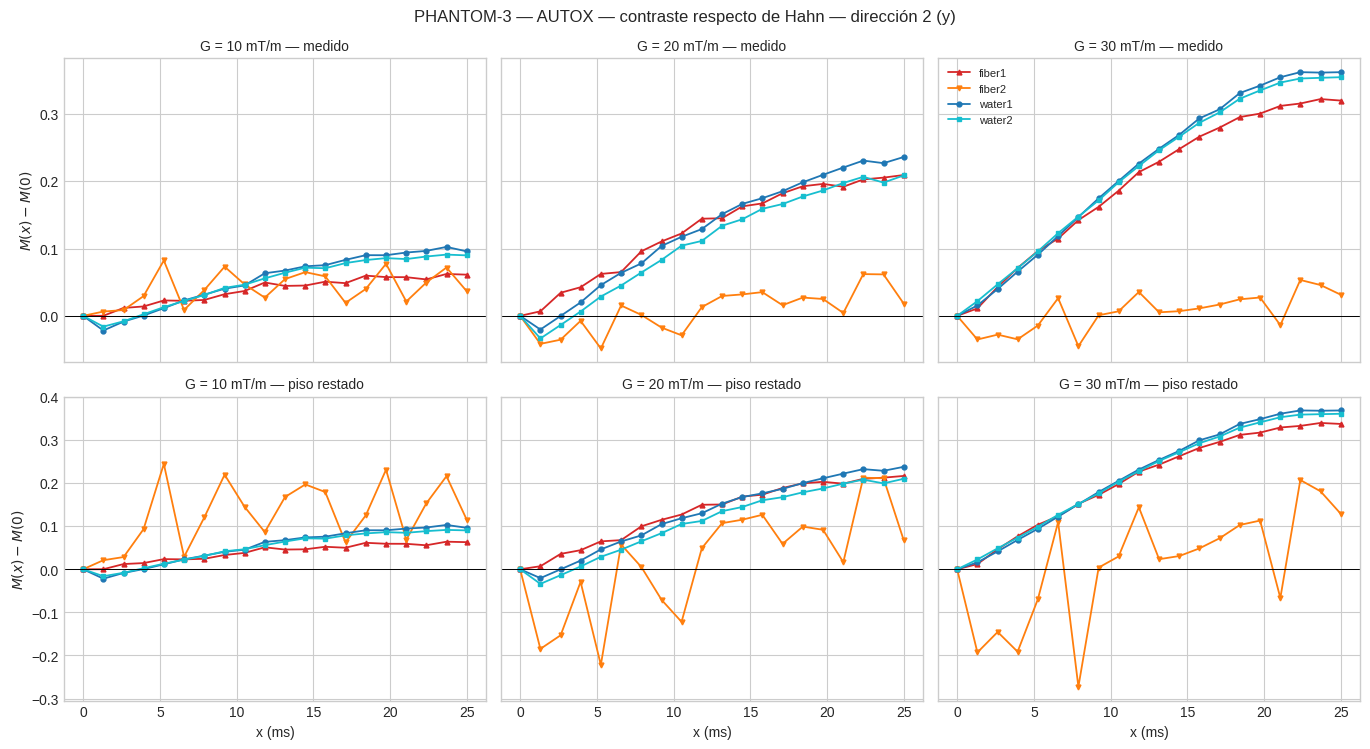

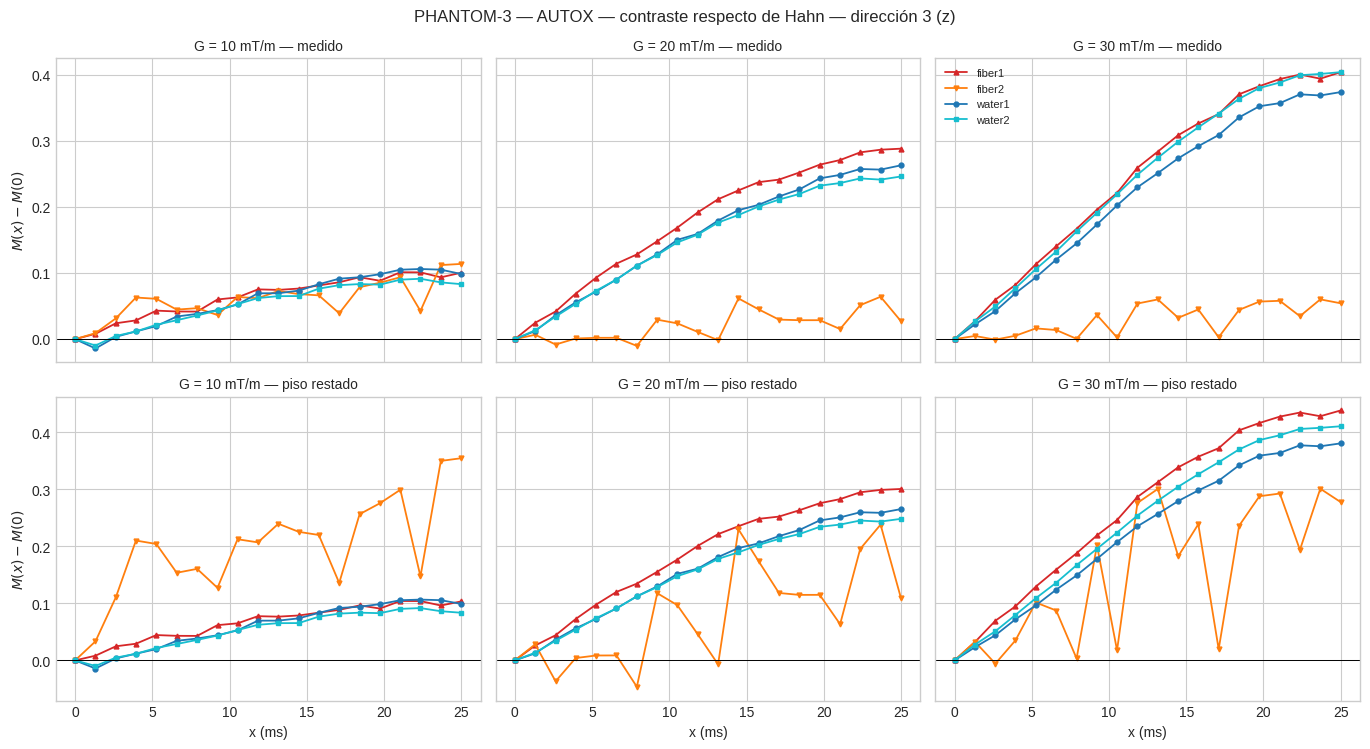

Figuras y tablas guardadas en: /mnt/storage/tier2/MUMI-EXT-001/mumi-data/Project-NOGSE/repos/signal_analysis/results/autox_plots/sub-PHANTOM-3/ses-20261026NOGSEV2003FOV220M128SL01R1AUTOX


In [6]:
for column in CORRECTIONS.values():
    at_zero = data.loc[np.isclose(data['x'], 0.0, atol=1e-6)].groupby(['roi', 'G', 'direction'])[column].mean()
    data[f'contrast_{column}'] = data[column] - pd.Series(
        list(zip(data['roi'], data['G'], data['direction']))).map(at_zero).to_numpy()

for direction in directions:
    fig, axes = plt.subplots(len(CORRECTIONS), len(g_values), figsize=(4.6 * len(g_values), 3.8 * len(CORRECTIONS)),
                             sharex=True, sharey='row', squeeze=False)
    for row, (correction, column) in enumerate(CORRECTIONS.items()):
        for col, g_value in enumerate(g_values):
            ax = axes[row, col]
            for roi in rois:
                curve = data.loc[data['roi'].eq(roi) & data['G'].eq(g_value) & data['direction'].eq(direction)]
                color, marker = roi_style(roi)
                plot_curve(ax, curve, f'contrast_{column}', color, marker, roi)
            ax.axhline(0, color='k', lw=0.7)
            ax.set_title(f'G = {g_value:g} mT/m — {correction}', fontsize=10)
            if row == len(CORRECTIONS) - 1:
                ax.set_xlabel('x (ms)')
            if col == 0:
                ax.set_ylabel('$M(x) - M(0)$')
    axes[0, -1].legend(fontsize=8)
    fig.suptitle(f'{SUB} — AUTOX — contraste respecto de Hahn — {direction_names.get(direction, direction)}', fontsize=12)
    fig.tight_layout()
    save_figure(fig, FIGURE_DIR, f'autox_contrast_direction-{direction}')
    plt.show()

data.to_csv(TABLE_DIR / 'autox_signals.csv', index=False)
print('Figuras y tablas guardadas en:', OUTPUT_ROOT)